# weewx / console / battery

**Intent**
- Takes `weatherstation_console_battery_voltage`, in volts.
- Optionally takes `weatherstation_console_battery_voltage_mean20`, a 20-reading mean of it.
- Outputs `weewx_console_battery_capacity_pct`, in percent from 0 to 100 in steps of 5.
- Exists to track the console battery without a gauge.

**Data**
- `training` is the 2024 run, 1,137 samples at 3 hour steps from 3.965 V down to the 3.000 V cutoff.
- It is digitised from the plot cached in git, revision 7ab8c7c7d, with pixels mapped through the axis ticks to about 0.003 V.
- It is a shape and not a measurement, and the arctan is fitted to it with the incumbent's 36 control points.
- `validation` is the 2026 run from InfluxDB, 813 on-change readings of one discharge.
- It runs from 4.17 V to a 3.76 to 3.80 V plateau, so it covers the top and the plateau only.
- `backtest` is those readings labelled by the incumbent Home Assistant curve.
- It shows agreement with what runs today, not battery truth.

**Status**
- The fixed-width arctan with a plateau shelf, in steps of 5, is selected for release.
- It is the only candidate inside both limits, rmse 5 and bounce 60, that works with the inputs Home Assistant sends today.
- Bounce is how often the output reverses direction on a one-way discharge.
- Its bounce is 45 against 464 without the shelf.
- It gives up tracking the capacity across the 3.77 to 3.83 V plateau, where the cell dwells.

**Future**
- Overall: the design holds across every phase:
  - Move to a stateful model that owns the smoothing, so Home Assistant sends the raw voltage, two timestamps and the saved state.
  - Smooth with a 1 hour exponential that decays the old reading through each gap and resets on a departure over 0.05 V.
  - Hold the output step with a margin of 1 point to fall and 3 to rise, measured at bounce 0 and rmse 2.54.
  - Carry four numbers of state, the smoothed voltage, the last reading time, the previous voltage and the held step.
  - Detect silence in the model from the reading's report time and the clock, and report zero capacity.
  - Accept that a restart loses the state, about one extra flip in four restarts, since the helpers were dropped.
  - Drop the optional mean input from the signature before release, since the stateful model replaces it.
  - Add a constant floor a consumer can act on without the network, and wire Home Assistant to the served model.
- Phase 1: now, before the real data, while the current battery drains:
  - Build the stateful model now as `wasm`, and replay the 2024 and 2026 runs through it to prove it before the real data.
  - Deploy it as a preview and enable the Home Assistant call, so it runs live on the current drain and records `model_version`.
  - Deploying needs `mlserver` to serve models, which it does not yet, so fix or release `mlserver` first.
  - Keep it a preview until the first refit, since a release fixes the signature and later releases change only the model file.
  - Data collection gates the refits below, so Home Assistant records every poll while the current battery drains.
  - Home Assistant records every poll's report time in an `input_number` helper, so cadence and silence can be replayed in training.
- Phase 2: when the current drain ends, about mid to late January 2027:
  - Wait about 10 to 12 weeks, until mid to late January 2027, for the drain to end and show the knee and the silence.
  - A full drain took about 140 days in 2024, with the knee in the last 15.
  - Then refresh the Data, retune the smoother and silence rule on the real cadence and knee, and release the first version.
- Phase 3: the next battery cycle, running to about June 2027:
  - Replace the battery once it is flat, which records the swap on the first reading and starts a fresh cycle.
  - That cycle takes about 140 days, to about June 2027, and adds a summer-to-winter run for a third full drain.
  - When it ends, replace the 2024 run in training with it, refit the arctan, and release the refit changing only the model file.
  - The run after that becomes the backtest, and each later run is replayed through the released model as it finishes.
- Phase 4: ongoing, as runs accumulate over the years:
  - Allocate each run to one split when it starts and never move it, so the held-out runs stay honest.
  - Until then the 2024 run trains the arctan shape and the 2026 run validates the smoother settings.
  - The backtest replays its run poll by poll through the finished model, judging bounce, silence and error against time-normalised capacity.
  - Log each run's battery brand, batch, install date and start voltage, so curve differences trace to wear or charge.
  - Compare runs on capacity normalised over time, and if they overlay fit one curve, otherwise add a per-battery offset.
  - Give a new battery type its own training and validation runs before judging it as backtest, which needs at least three runs.
  - Run at least one full cycle on any new battery type before trusting the curve for it.
  - Refresh the Data as a new timestamped capture of each finished run, committed so a re-query shows as a diff.
  - A run that has judged this model joins training only in a new notebook with its own splits.
  - Keep Home Assistant recording every poll, and check InfluxDB retention and gaps, so no run is lost.

## Setup ([6.7.1](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#671-setup))

In [29]:
from workbench.data import data_path, golden_data, query_influxdb3, read_data
from workbench.env import init_env
from workbench.plot import show_curves, show_error_plot, show_plot
from workbench.project import load_signature, provenance, record_project, scratch_project_dir, signature_names

env = init_env()

WORKSPACE = "weewx/console/battery"
MODEL_NAME = "weewx_console_battery"
TARGET = {"kind": "served"}
signature = load_signature(WORKSPACE)
INPUTS, OUTPUTS = signature_names(signature)
MEAN_INPUT = INPUTS[1]
MEAN_WINDOW = 20
TRAINING = "console_battery_voltage_2024-06-06_2024-10-25"
VALIDATION = "console_battery_voltage_2026-08-13_2026-10-30"
GOLDEN = "console_battery_voltage_golden"

workspace weewx/console/battery
flavour   pyfunc
target    served
runtime   none
version   10.200.1996-SNAPSHOT (unreleased)
inputs    weatherstation_console_battery_voltage [volts]
          weatherstation_console_battery_voltage_mean20 [volts]
outputs   weewx_console_battery_capacity_pct [percent]


## Capture Data ([6.7.2](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#672-capture-data))

In [30]:
query_influxdb3(
    env,
    """
SELECT time, value
FROM sensor__voltage
WHERE module = 'homeassistant'
  AND entity_id = 'weatherstation_console_battery_voltage'
  AND time >= '2026-08-13T00:00:00Z'
  AND time < '2026-10-31T00:00:00Z'
ORDER BY time
""",
    WORKSPACE,
    "validation",
    VALIDATION,
)

import polars as pl

data_training_path = data_path(WORKSPACE, "training", TRAINING)
data_raw_pl = read_data(WORKSPACE, "training", TRAINING).rename({"time": "Timestamp", "voltage": "Voltage"}).with_columns(pl.col("Voltage").cast(pl.Float32))
data_validation_pl = read_data(WORKSPACE, "validation", VALIDATION).rename({"time": "Timestamp", "value": "Voltage"}).with_columns(pl.col("Voltage").cast(pl.Float32))

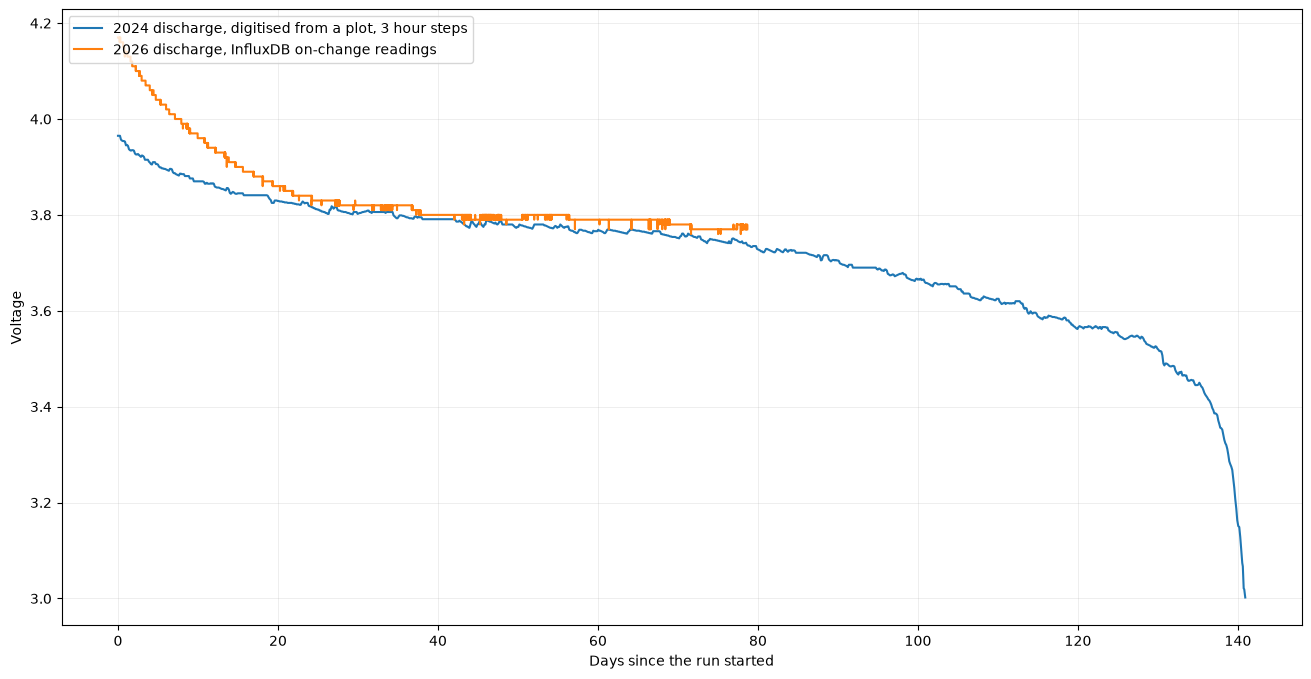

In [31]:
def days_since_start(frame):
    return (frame["Timestamp"] - frame["Timestamp"].min()).dt.total_seconds() / 86400


show_curves(
    [
        ("2024 discharge, digitised from a plot, 3 hour steps", days_since_start(data_raw_pl), data_raw_pl["Voltage"], {"color": "tab:blue", "linewidth": 1.5}),
        ("2026 discharge, InfluxDB on-change readings", days_since_start(data_validation_pl), data_validation_pl["Voltage"], {"drawstyle": "steps-post", "color": "tab:orange", "linewidth": 1.5}),
    ],
    "Days since the run started",
    "Voltage",
)

## Explore ([6.7.3](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#673-explore))

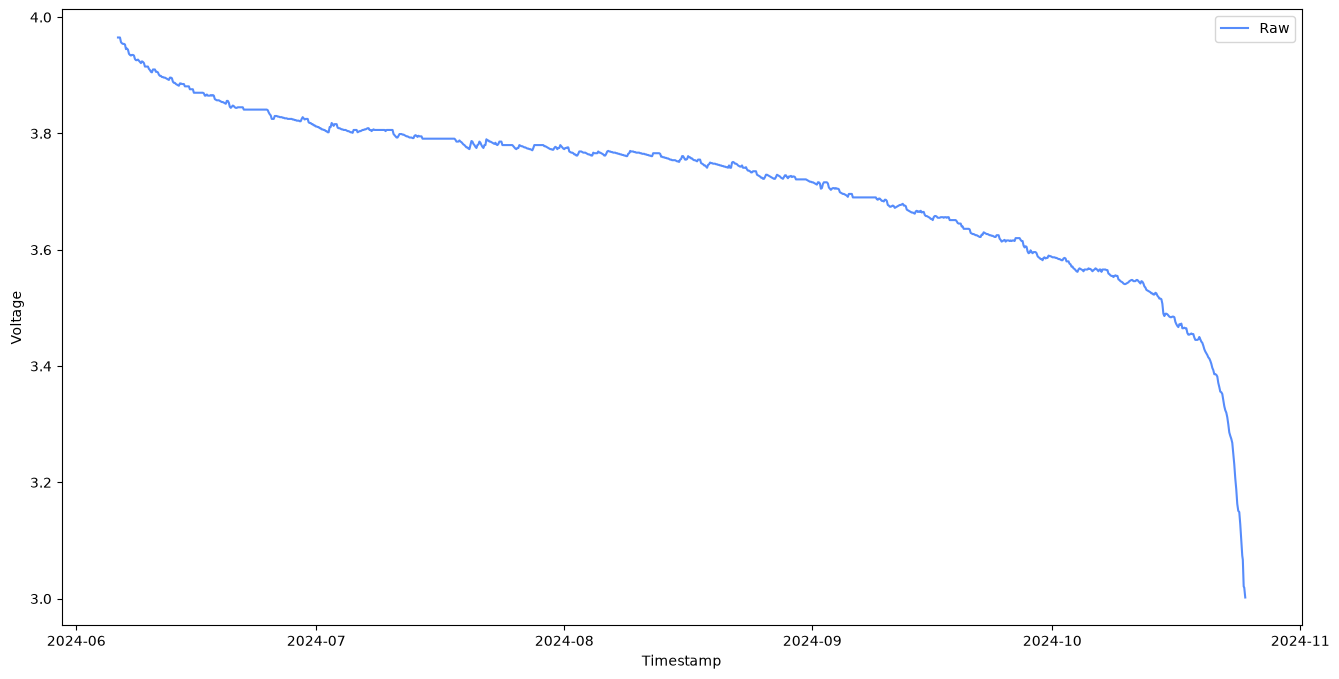

In [32]:
show_plot("Raw", data_raw_pl, "Timestamp", "Voltage")

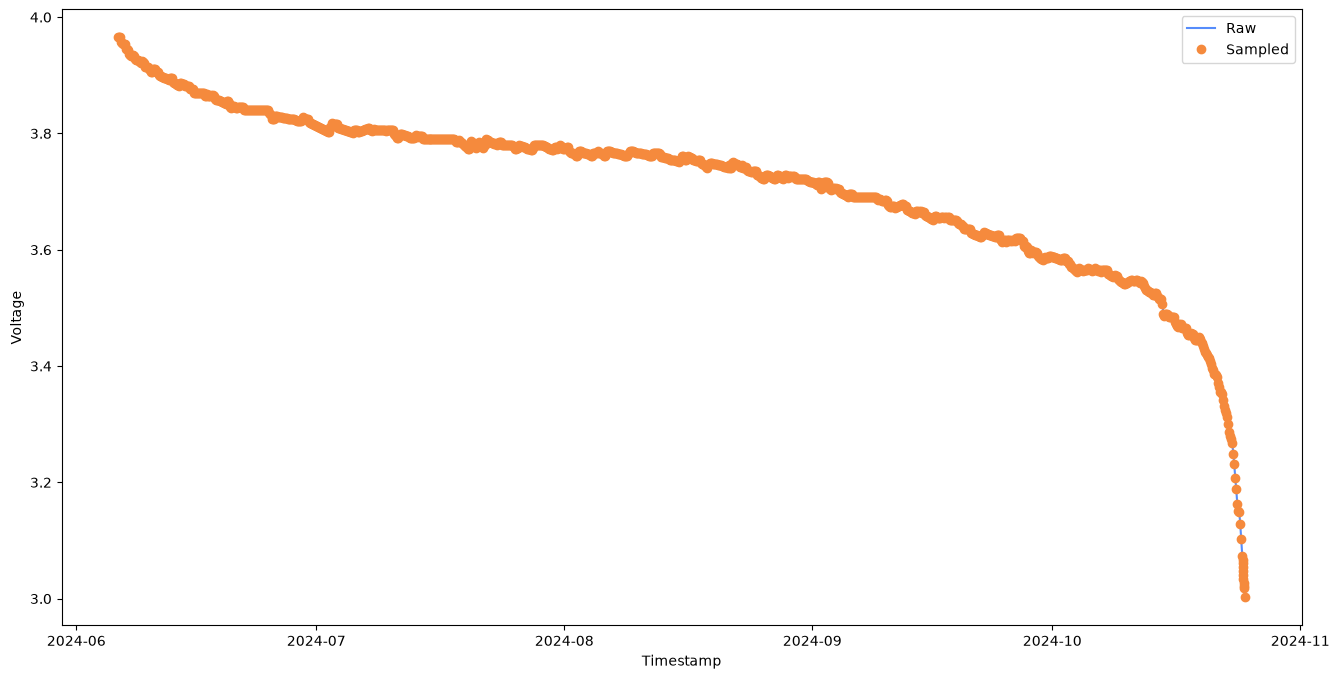

In [33]:
data_sampled_pl = data_raw_pl.sort("Timestamp").group_by_dynamic("Timestamp", every="10m").agg(pl.col("Voltage").min())
show_plot("Raw", data_raw_pl, "Timestamp", "Voltage")
show_plot("Sampled", data_sampled_pl, "Timestamp", "Voltage", "o")

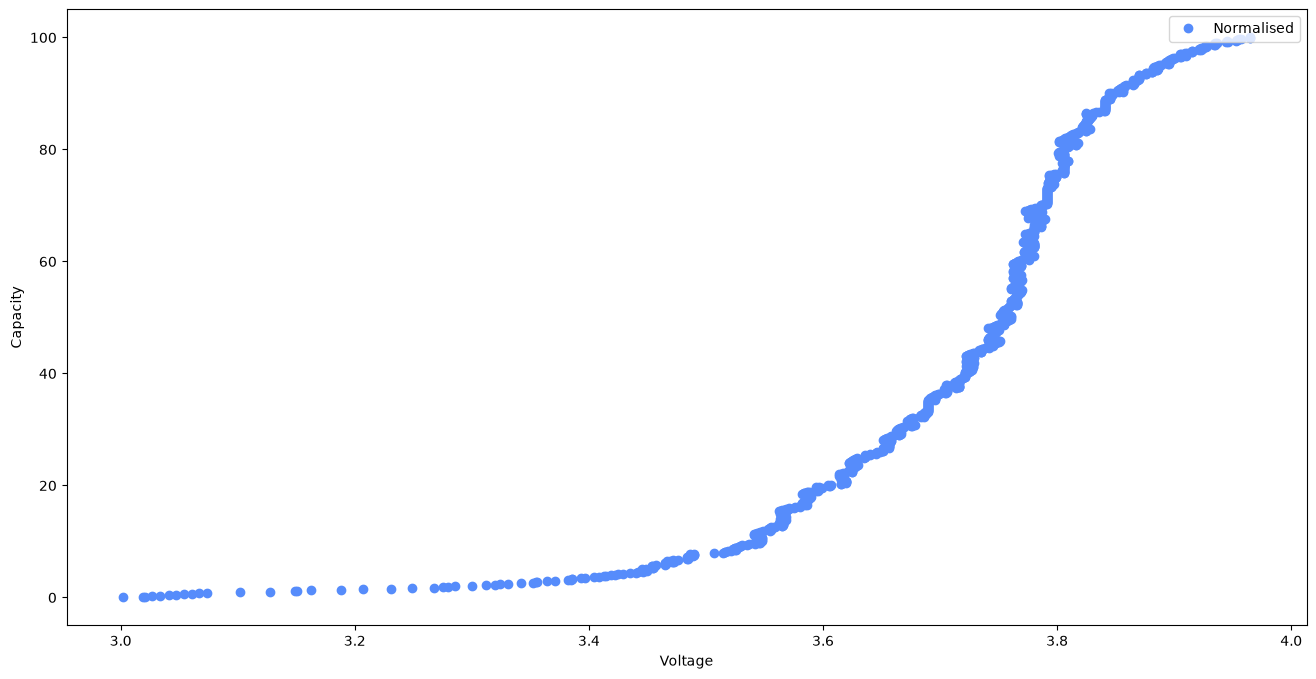

In [34]:
data_normalised_pl = data_sampled_pl.drop("Timestamp").with_row_index("Capacity")
data_normalised_pl = data_normalised_pl.with_columns((100 - pl.col("Capacity") / pl.max("Capacity") * 100).alias("Capacity"))
show_plot("Normalised", data_normalised_pl, "Voltage", "Capacity", "o")

## Fit ([6.7.4](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#674-fit))

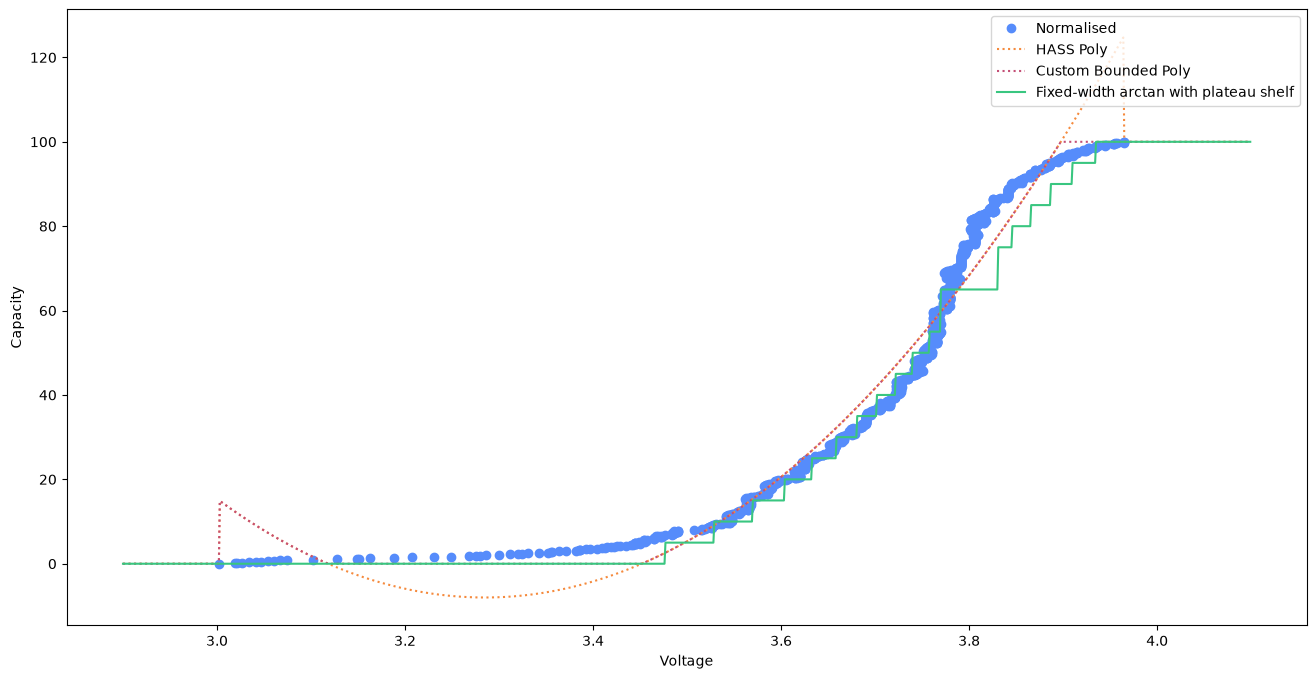

In [35]:
from math import atan

import numpy as np
from scipy.optimize import curve_fit

y_min = 0.0
y_max = 100.0
y_data = data_normalised_pl.select("Capacity").to_numpy().flatten()
x_min = data_normalised_pl.select(pl.min("Voltage")).item()
x_max = data_normalised_pl.select(pl.max("Voltage")).item()
x_data = data_normalised_pl.select("Voltage").to_numpy().flatten()
incumbent_points = np.array(
    [
        [4, 100],
        [3.97, 99],
        [3.95, 98],
        [3.92, 96],
        [3.91, 94],
        [3.9, 93],
        [3.89, 91],
        [3.88, 88],
        [3.87, 87],
        [3.85, 83],
        [3.83, 81],
        [3.81, 65],
        [3.79, 59],
        [3.78, 56],
        [3.76, 50],
        [3.75, 49],
        [3.74, 43],
        [3.72, 38],
        [3.7, 35],
        [3.68, 33],
        [3.66, 28],
        [3.64, 22],
        [3.62, 21],
        [3.61, 18],
        [3.59, 16],
        [3.58, 15],
        [3.56, 10],
        [3.54, 9],
        [3.52, 8],
        [3.49, 7],
        [3.48, 6],
        [3.46, 5],
        [3.44, 3],
        [3.4, 2],
        [3.38, 1],
        [3.32, 0],
    ]
)
x_fit = np.concatenate([x_data, incumbent_points[:, 0]])
y_fit = np.concatenate([y_data, incumbent_points[:, 1]])
sigma_fit = np.concatenate([np.ones(len(x_data)), np.full(len(incumbent_points), (len(incumbent_points) / len(x_data)) ** 0.5)])

fit_poly_coefficients = np.polyfit(x_data, y_data, 2)
fit_poly_function = np.poly1d(fit_poly_coefficients)


def fit_hass_poly_function(x):
    if x < x_min:
        return y_min
    if x > x_max:
        return y_max
    return fit_poly_function(x)


def fit_custom_bounded_poly_function(x):
    if x < x_min:
        return y_min
    if x > x_max:
        return y_max
    y = fit_poly_function(x)
    if y < y_min:
        return y_min
    if y > y_max:
        return y_max
    return y


ARCTAN_WIDTH = 5.0
SHELF_LOW = 3.77
SHELF_HIGH = 3.83
SHELF_CENTRE = 0.5 * (SHELF_LOW + SHELF_HIGH)


def fit_custom_arctan(x, k, x0, y0):
    return k * np.arctan(ARCTAN_WIDTH * (x - x0)) + y0


fit_arctan_coefficients = curve_fit(fit_custom_arctan, x_fit, y_fit, p0=[30.0, 0.5 * (x_max + x_min), 0.5 * (y_max + y_min)], sigma=sigma_fit, full_output=True)[0]


def fit_free_width_arctan(x, k, w, x0, y0):
    return k * np.arctan(w * (x - x0)) + y0


fit_free_width_arctan_coefficients = curve_fit(fit_free_width_arctan, x_fit, y_fit, p0=[1, 1, 0.5 * (x_max + x_min), 0.5 * (y_max + y_min)], sigma=sigma_fit)[0]


def fit_free_width_stepped_arctan(x):
    if x < x_min:
        return y_min
    if x > x_max:
        return y_max
    y = fit_free_width_arctan(x, *fit_free_width_arctan_coefficients)
    if y < y_min:
        return y_min
    if y > y_max:
        return y_max
    return float(int(y) // 5 * 5)


def fit_arctan_with_shelf(x):
    if x < x_min:
        return y_min
    if x > x_max:
        return y_max
    if SHELF_LOW <= x <= SHELF_HIGH:
        x = SHELF_CENTRE
    y = fit_arctan_coefficients[0] * atan(ARCTAN_WIDTH * (x - fit_arctan_coefficients[1])) + fit_arctan_coefficients[2]
    if y < y_min:
        return y_min
    if y > y_max:
        return y_max
    return float(int(y) // 5 * 5)


scale_factor = 1000
data_fitted_pl = pl.arange(2.9 * scale_factor, 4.1 * scale_factor, eager=True).to_frame("Voltage").with_columns(pl.col("Voltage") / scale_factor)
data_fitted_hass_poly_pl = data_fitted_pl.with_columns(pl.col("Voltage").map_elements(lambda x: fit_hass_poly_function(x), return_dtype=pl.Float64).alias("Capacity"))
data_fitted_custom_bounded_poly_pl = data_fitted_pl.with_columns(pl.col("Voltage").map_elements(lambda x: fit_custom_bounded_poly_function(x), return_dtype=pl.Float64).alias("Capacity"))
data_fitted_arctan_with_shelf_pl = data_fitted_pl.with_columns(pl.col("Voltage").map_elements(lambda x: fit_arctan_with_shelf(x), return_dtype=pl.Float64).alias("Capacity"))

show_plot("Normalised", data_normalised_pl, "Voltage", "Capacity", "o")
show_plot("HASS Poly", data_fitted_hass_poly_pl, "Voltage", "Capacity", ":")
show_plot("Custom Bounded Poly", data_fitted_custom_bounded_poly_pl, "Voltage", "Capacity", ":")
show_plot("Fixed-width arctan with plateau shelf", data_fitted_arctan_with_shelf_pl, "Voltage", "Capacity", "-")

## Evaluate ([6.7.5](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#675-evaluate))

In [36]:
import importlib.util
from os.path import join

from workbench.config import NOTEBOOK_DIR

MODEL_TEMPLATE = """from math import atan

import pandas as pd
from mlflow.models import set_model
from mlflow.pyfunc import PythonModel

INPUT = "weatherstation_console_battery_voltage"
OUTPUT = "weewx_console_battery_capacity_pct"
MEAN_INPUT = {mean_input!r}
X_MIN = {x_min!r}
X_MAX = {x_max!r}
Y_MIN = {y_min!r}
Y_MAX = {y_max!r}
STEP = 5
SHELF_LOW = {shelf_low!r}
SHELF_HIGH = {shelf_high!r}
SHELF_CENTRE = 0.5 * (SHELF_LOW + SHELF_HIGH)
K = {k!r}
W = {w!r}
X0 = {x0!r}
Y0 = {y0!r}


def capacity_pct(voltage, mean=None):
    smoothed = mean is not None and mean == mean
    reading = mean if smoothed else voltage
    if reading < X_MIN:
        return Y_MIN
    if reading > X_MAX:
        return Y_MAX
    if not smoothed and SHELF_LOW <= reading <= SHELF_HIGH:
        reading = SHELF_CENTRE
    capacity = K * atan(W * (reading - X0)) + Y0
    if capacity < Y_MIN:
        return Y_MIN
    if capacity > Y_MAX:
        return Y_MAX
    return float(int(capacity) // STEP * STEP)


class ConsoleBattery(PythonModel):
    def predict(self, context, model_input: pd.DataFrame, params=None):
        means = model_input[MEAN_INPUT] if MEAN_INPUT in model_input.columns else [None] * len(model_input)
        return pd.DataFrame({{OUTPUT: [capacity_pct(voltage, mean) for voltage, mean in zip(model_input[INPUT], means, strict=True)]}})


set_model(ConsoleBattery())
"""

model_path = join(NOTEBOOK_DIR, WORKSPACE, "model.py")
with open(model_path, "w") as model_file:
    model_file.write(
        MODEL_TEMPLATE.format(
            x_min=float(x_min),
            x_max=float(x_max),
            y_min=y_min,
            y_max=y_max,
            mean_input=MEAN_INPUT,
            shelf_low=SHELF_LOW,
            shelf_high=SHELF_HIGH,
            k=float(fit_arctan_coefficients[0]),
            w=ARCTAN_WIDTH,
            x0=float(fit_arctan_coefficients[1]),
            y0=float(fit_arctan_coefficients[2]),
        )
    )
model_spec = importlib.util.spec_from_file_location("model", model_path)
model = importlib.util.module_from_spec(model_spec)
model_spec.loader.exec_module(model)
capacity_pct = model.capacity_pct

assert all(capacity_pct(v) == fit_arctan_with_shelf(v) for v in np.linspace(x_min - 0.2, x_max + 0.2, 500)), "the shipped function differs from the fitted function"

validation_capacity = [capacity_pct(v) for v in data_validation_pl["Voltage"].to_list()]
validation_rises = sum(1 for a, b in zip(validation_capacity, validation_capacity[1:], strict=False) if b > a)
print("validation samples", len(validation_capacity), "capacity range", min(validation_capacity), max(validation_capacity), "step rises on a one-way discharge", validation_rises)
assert min(validation_capacity) >= 0.0 and max(validation_capacity) <= 100.0

validation samples 813 capacity range 55.0 100.0 step rises on a one-way discharge 60


In [37]:
from glob import glob

import pandas as pd

from workbench.model import evaluate_acceptance, measure

BACKTEST = sorted(glob(join(NOTEBOOK_DIR, WORKSPACE, "data", "backtest", "*", "*.csv")))


def acceptance_checks():
    backtest = pd.read_csv(BACKTEST[-1])
    arctan_with_shelf = [capacity_pct(voltage) for voltage in backtest["weatherstation_console_battery_voltage"]]
    measured = measure(backtest["incumbent_capacity_pct"], arctan_with_shelf)
    moves = [after - before for before, after in zip(arctan_with_shelf, arctan_with_shelf[1:], strict=False) if after != before]
    bounce = sum(1 for before, after in zip(moves, moves[1:], strict=False) if before * after < 0)
    means = backtest["weatherstation_console_battery_voltage"].rolling(MEAN_WINDOW, min_periods=MEAN_WINDOW).mean()
    arctan_on_mean = [capacity_pct(voltage, None if pd.isna(mean) else mean) for voltage, mean in zip(backtest["weatherstation_console_battery_voltage"], means, strict=True)]
    moves_mean = [after - before for before, after in zip(arctan_on_mean, arctan_on_mean[1:], strict=False) if after != before]
    bounce_mean = sum(1 for before, after in zip(moves_mean, moves_mean[1:], strict=False) if before * after < 0)
    return [
        {"split": "backtest", "output": "weewx_console_battery_capacity_pct", "name": "rmse", "value": measured["rmse"], "limit": 5, "direction": "max"},
        {"split": "backtest", "output": "weewx_console_battery_capacity_pct", "name": "bounce", "value": float(bounce), "limit": 60, "direction": "max"},
        {
            "split": "backtest",
            "output": "weewx_console_battery_capacity_pct",
            "name": "rmse_mean20",
            "value": measure(backtest["incumbent_capacity_pct"], arctan_on_mean)["rmse"],
            "limit": 5,
            "direction": "max",
        },
        {"split": "backtest", "output": "weewx_console_battery_capacity_pct", "name": "bounce_mean20", "value": float(bounce_mean), "limit": 10, "direction": "max"},
    ]


evaluation = evaluate_acceptance(acceptance_checks, {"backtest": BACKTEST})
for entry in evaluation["checks"]:
    print(entry["split"], entry["output"], entry["name"], "measured", entry["value"], "passed", entry["passed"])
print("acceptance", "passed" if evaluation["passed"] else "failed, the shipped model differs from the incumbent curve by more than the limit")

acceptance [passed] budget [0.7514807031670689]
backtest weewx_console_battery_capacity_pct rmse measured 3.7574035158353447 passed True
backtest weewx_console_battery_capacity_pct bounce measured 45.0 passed True
backtest weewx_console_battery_capacity_pct rmse_mean20 measured 2.7432125787391177 passed True
backtest weewx_console_battery_capacity_pct bounce_mean20 measured 0.0 passed True
acceptance passed


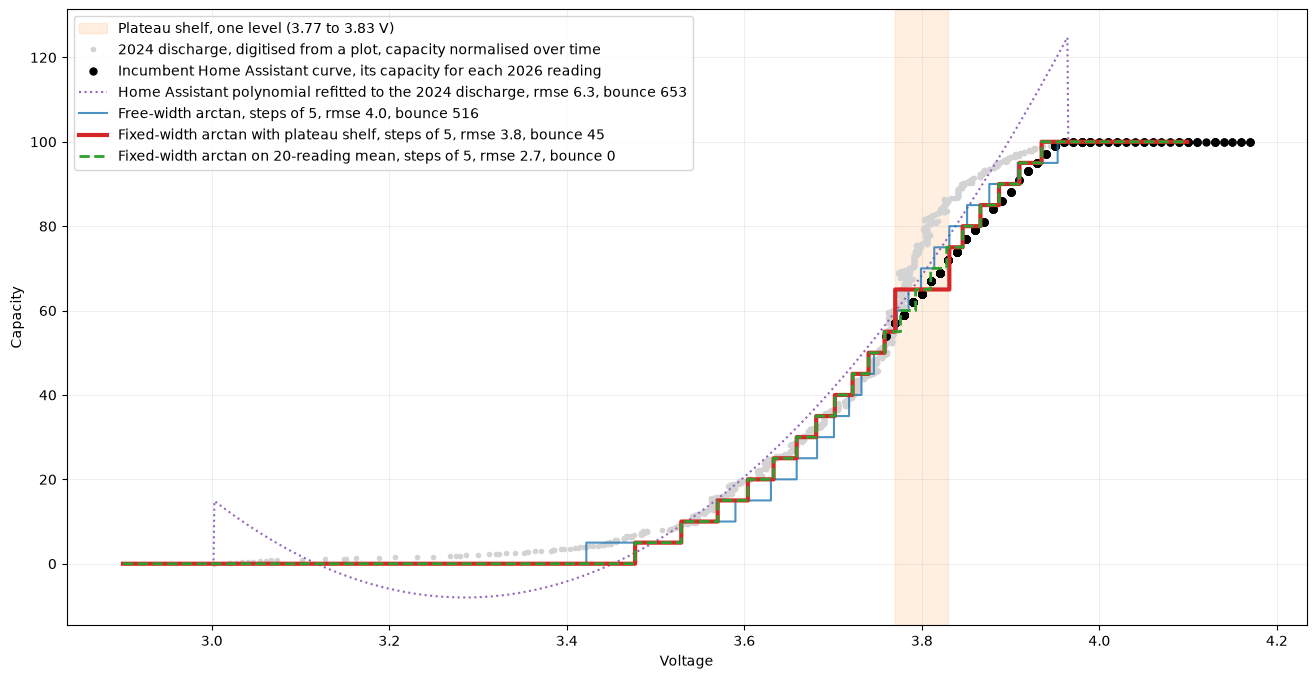

In [38]:
data_arctan_with_shelf_pl = data_fitted_pl.with_columns(pl.col("Voltage").map_elements(capacity_pct, return_dtype=pl.Float64).alias("Capacity"))
data_arctan_on_mean_pl = data_fitted_pl.with_columns(pl.col("Voltage").map_elements(lambda x: capacity_pct(x, x), return_dtype=pl.Float64).alias("Capacity"))
data_free_width_arctan_pl = data_fitted_pl.with_columns(pl.col("Voltage").map_elements(fit_free_width_stepped_arctan, return_dtype=pl.Float64).alias("Capacity"))
data_backtest_pl = pl.read_csv(BACKTEST[-1]).rename({"weatherstation_console_battery_voltage": "Voltage", "incumbent_capacity_pct": "Incumbent"})
data_backtest_pl = data_backtest_pl.with_columns(
    pl.col("Voltage").rolling_mean(MEAN_WINDOW).alias("Voltage Mean"),
).with_columns(
    pl.col("Voltage").map_elements(capacity_pct, return_dtype=pl.Float64).alias("Arctan With Shelf"),
    pl.col("Voltage").map_elements(fit_free_width_stepped_arctan, return_dtype=pl.Float64).alias("Free Width Arctan"),
    pl.col("Voltage").map_elements(fit_hass_poly_function, return_dtype=pl.Float64).alias("Poly"),
    pl.struct("Voltage", "Voltage Mean").map_elements(lambda row: capacity_pct(row["Voltage"], row["Voltage Mean"]), return_dtype=pl.Float64).alias("Arctan On Mean"),
)
data_backtest_pl = data_backtest_pl.with_columns((pl.col("Arctan With Shelf") - pl.col("Incumbent")).alias("Error"))


def named(label, column):
    values = data_backtest_pl[column].to_numpy()
    moves = np.diff(values)
    moves = moves[moves != 0]
    return f"{label}, rmse {np.sqrt(np.mean((values - data_backtest_pl['Incumbent'].to_numpy()) ** 2)):.1f}, bounce {int((moves[1:] * moves[:-1] < 0).sum())}"


show_curves(
    [
        (
            "2024 discharge, digitised from a plot, capacity normalised over time",
            data_normalised_pl["Voltage"],
            data_normalised_pl["Capacity"],
            {"marker": ".", "linestyle": "none", "color": "lightgray"},
        ),
        (
            "Incumbent Home Assistant curve, its capacity for each 2026 reading",
            data_backtest_pl["Voltage"],
            data_backtest_pl["Incumbent"],
            {"marker": "o", "linestyle": "none", "color": "black", "markersize": 5},
        ),
        (
            named("Home Assistant polynomial refitted to the 2024 discharge", "Poly"),
            data_fitted_hass_poly_pl["Voltage"],
            data_fitted_hass_poly_pl["Capacity"],
            {"linestyle": ":", "color": "tab:purple"},
        ),
        (
            named("Free-width arctan, steps of 5", "Free Width Arctan"),
            data_free_width_arctan_pl["Voltage"],
            data_free_width_arctan_pl["Capacity"],
            {"drawstyle": "steps-post", "color": "tab:blue", "alpha": 0.8},
        ),
        (
            named("Fixed-width arctan with plateau shelf, steps of 5", "Arctan With Shelf"),
            data_arctan_with_shelf_pl["Voltage"],
            data_arctan_with_shelf_pl["Capacity"],
            {"drawstyle": "steps-post", "color": "tab:red", "linewidth": 3},
        ),
        (
            named("Fixed-width arctan on 20-reading mean, steps of 5", "Arctan On Mean"),
            data_arctan_on_mean_pl["Voltage"],
            data_arctan_on_mean_pl["Capacity"],
            {"drawstyle": "steps-post", "color": "tab:green", "linestyle": "--", "linewidth": 2},
        ),
    ],
    "Voltage",
    "Capacity",
    band=(SHELF_LOW, SHELF_HIGH),
    band_label="Plateau shelf, one level (3.77 to 3.83 V)",
)

In [ ]:
from math import exp

validation_seconds = ((data_validation_pl["Timestamp"] - data_validation_pl["Timestamp"].min()).dt.total_seconds()).to_list()
assert np.allclose(data_validation_pl["Voltage"].to_numpy(), data_backtest_pl["Voltage"].to_numpy(), atol=1e-4), "the backtest readings are the validation readings"


def continuous_capacity(voltage):
    if voltage < x_min:
        return y_min
    if voltage > x_max:
        return y_max
    capacity = fit_arctan_coefficients[0] * atan(ARCTAN_WIDTH * (voltage - fit_arctan_coefficients[1])) + fit_arctan_coefficients[2]
    return min(max(capacity, y_min), y_max)


def stateful_exponential(seconds, voltages, tau_seconds=3600, fall_margin=1.0, rise_margin=3.0, restart_seconds=None):
    outputs, smoothed, last, earlier, held = [], None, None, None, None
    next_restart = None if restart_seconds is None else seconds[0] + restart_seconds
    for second, voltage in zip(seconds, voltages, strict=True):
        if next_restart is not None and second >= next_restart:
            smoothed, held = None, None
            next_restart += restart_seconds
        previous, smoothed = smoothed, voltage
        if previous is not None and abs(voltage - previous) <= 0.05:
            smoothed = earlier + (previous - earlier) * exp(-(second - last) / tau_seconds)
        last, earlier = second, voltage
        capacity = continuous_capacity(smoothed)
        if held is None or capacity <= y_min or capacity >= y_max or capacity < held - fall_margin or capacity > held + 5 + rise_margin:
            held = float(int(capacity) // 5 * 5)
        outputs.append(held)
    return outputs

In [39]:
incumbent = data_backtest_pl["Incumbent"].to_numpy()
backtest_voltages = data_backtest_pl["Voltage"].to_list()
training_voltages = data_normalised_pl["Voltage"].to_list()
training_capacity = data_normalised_pl["Capacity"].to_numpy()
RMSE_LIMIT = evaluation["checks"][0]["limit"]
BOUNCE_LIMIT = evaluation["checks"][1]["limit"]


def compare(name, backtest_outputs, training_outputs=None):
    error = np.asarray(backtest_outputs) - incumbent
    moves = np.diff(backtest_outputs)
    moves = moves[moves != 0]
    bounce = int((moves[1:] * moves[:-1] < 0).sum())
    rmse = float(np.sqrt(np.mean(error**2)))
    training_error = None if training_outputs is None else np.asarray(training_outputs) - training_capacity
    return {
        "Model": name,
        "Bounce": bounce,
        "RMSE vs incumbent": round(rmse, 2),
        "P95 error vs incumbent": round(float(np.percentile(np.abs(error), 95)), 1),
        "Max error vs incumbent": round(float(np.abs(error).max()), 1),
        "RMSE vs 2024": None if training_error is None else round(float(np.sqrt(np.mean(training_error**2))), 2),
        "Max error vs 2024": None if training_error is None else round(float(np.abs(training_error).max()), 1),
        f"Within limits, RMSE {RMSE_LIMIT:g} and bounce {BOUNCE_LIMIT:g}": "Yes" if rmse <= RMSE_LIMIT and bounce <= BOUNCE_LIMIT else "No",
    }


pl.Config.set_fmt_str_lengths(80)
pl.DataFrame(
    [
        compare("Home Assistant polynomial", [fit_hass_poly_function(v) for v in backtest_voltages], [fit_hass_poly_function(v) for v in training_voltages]),
        compare("Bounded polynomial", [fit_custom_bounded_poly_function(v) for v in backtest_voltages], [fit_custom_bounded_poly_function(v) for v in training_voltages]),
        compare("Free-width arctan, steps of 5", [fit_free_width_stepped_arctan(v) for v in backtest_voltages], [fit_free_width_stepped_arctan(v) for v in training_voltages]),
        compare("Fixed-width arctan, steps of 5", [capacity_pct(v, v) for v in backtest_voltages], [capacity_pct(v, v) for v in training_voltages]),
        compare("Fixed-width arctan with plateau shelf, steps of 5", [capacity_pct(v) for v in backtest_voltages], [capacity_pct(v) for v in training_voltages]),
        compare("Fixed-width arctan on 20-reading mean, steps of 5", data_backtest_pl["Arctan On Mean"].to_numpy()),
        compare("Stateful exponential 1 h, asymmetric hold, state in helpers", stateful_exponential(validation_seconds, backtest_voltages)),
        compare("Stateful exponential 1 h, asymmetric hold, state lost every 3 days", stateful_exponential(validation_seconds, backtest_voltages, restart_seconds=3 * 86400)),
    ]
)

Model,Bounce,RMSE vs incumbent,P95 error vs incumbent,Max error vs incumbent,RMSE vs 2024,Max error vs 2024,"Within limits, RMSE 5 and bounce 60"
str,i64,f64,f64,f64,f64,f64,str
"""Home Assistant polynomial""",653,6.26,15.1,23.2,6.0,25.3,"""No"""
"""Bounded polynomial""",616,4.6,7.0,12.0,5.15,15.0,"""No"""
"""Free-width arctan, steps of 5""",516,4.04,6.0,6.0,5.61,12.6,"""No"""
"""Fixed-width arctan, steps of 5""",464,1.78,3.0,4.0,6.91,17.2,"""No"""
"""Fixed-width arctan with platea…",45,3.76,8.0,8.0,7.05,21.4,"""Yes"""
"""Fixed-width arctan on 20-readi…",0,2.74,6.0,11.0,null,null,"""Yes"""


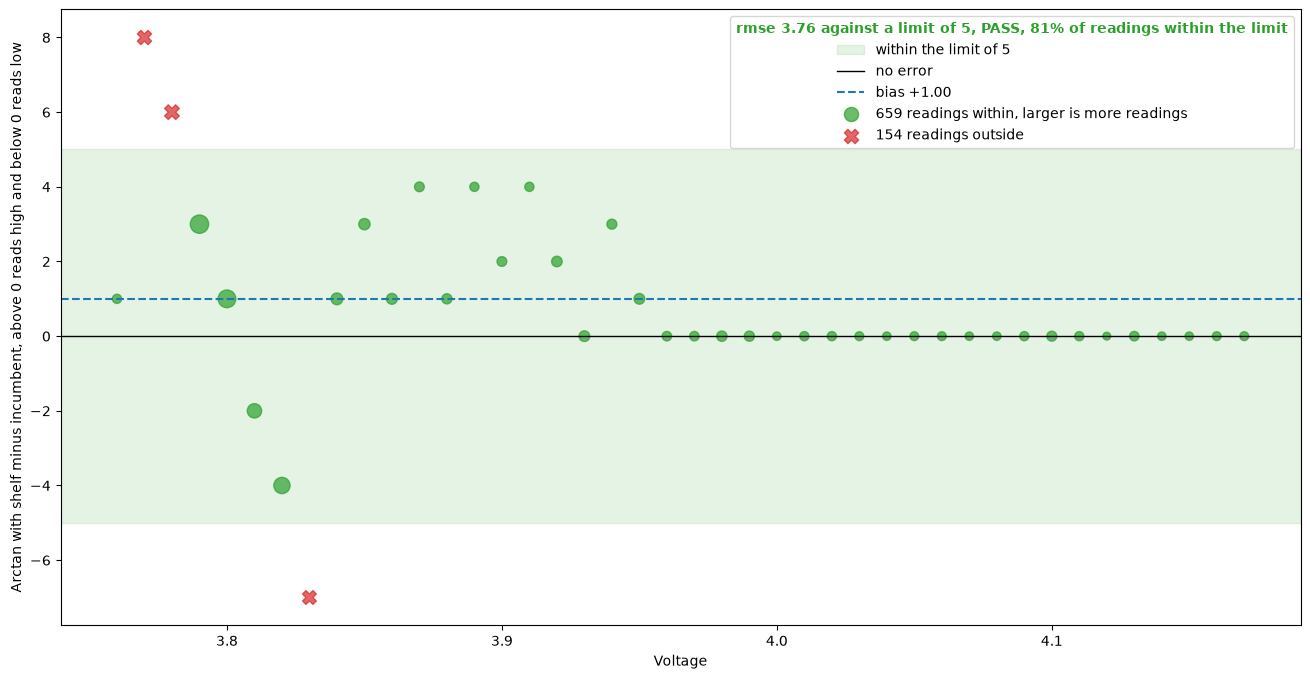

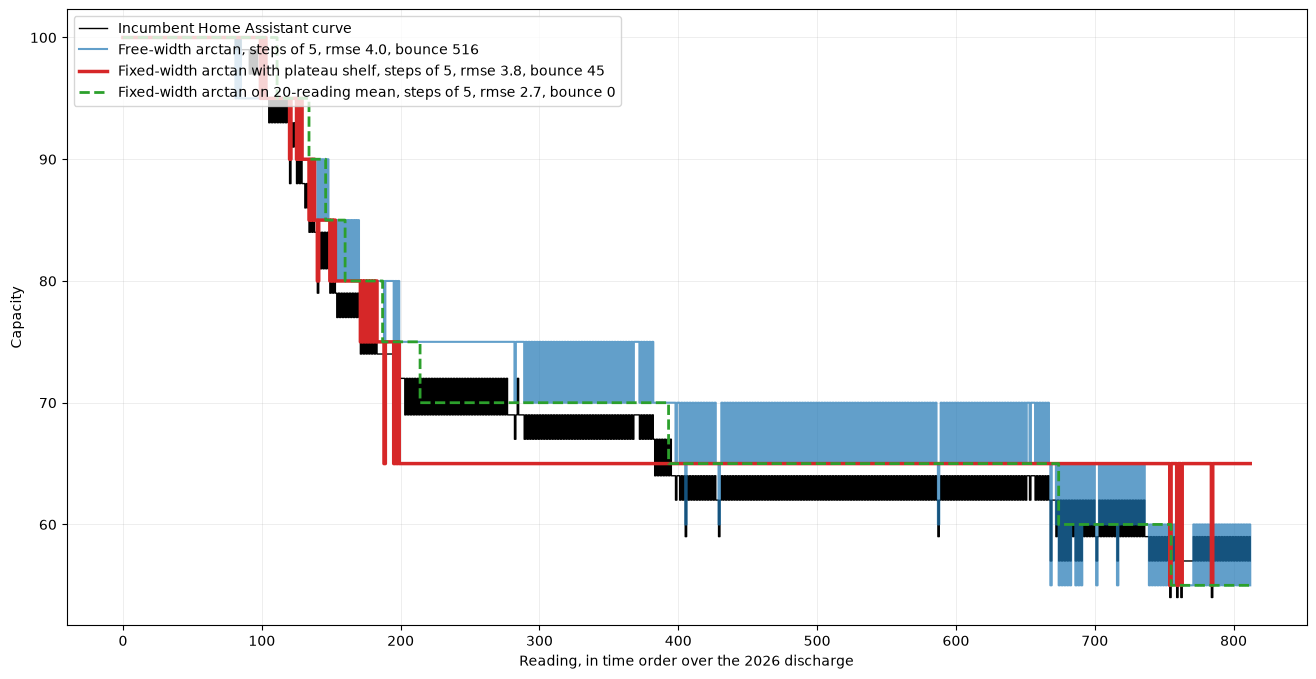

In [40]:
show_error_plot("Arctan with shelf minus incumbent", data_backtest_pl, "Voltage", "Error", evaluation["checks"][0]["limit"])
reading_index = np.arange(data_backtest_pl.height)
show_curves(
    [
        ("Incumbent Home Assistant curve", reading_index, data_backtest_pl["Incumbent"], {"drawstyle": "steps-post", "color": "black", "linewidth": 1}),
        (named("Free-width arctan, steps of 5", "Free Width Arctan"), reading_index, data_backtest_pl["Free Width Arctan"], {"drawstyle": "steps-post", "color": "tab:blue", "alpha": 0.7}),
        (
            named("Fixed-width arctan with plateau shelf, steps of 5", "Arctan With Shelf"),
            reading_index,
            data_backtest_pl["Arctan With Shelf"],
            {"drawstyle": "steps-post", "color": "tab:red", "linewidth": 2.5},
        ),
        (
            named("Fixed-width arctan on 20-reading mean, steps of 5", "Arctan On Mean"),
            reading_index,
            data_backtest_pl["Arctan On Mean"],
            {"drawstyle": "steps-post", "color": "tab:green", "linestyle": "--", "linewidth": 2},
        ),
    ],
    "Reading, in time order over the 2026 discharge",
    "Capacity",
)

## Package ([6.7.6](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#676-package))

In [41]:
import json

from workbench.model import package_project, register_preview
from workbench.replay import require_replay


def golden_samples():
    voltages = [round(v, 4) for v in [x_min - 0.1, x_min, *np.linspace(x_min, x_max, 40).tolist(), SHELF_LOW - 0.001, SHELF_LOW, SHELF_CENTRE, SHELF_HIGH, SHELF_HIGH + 0.001, x_max, x_max + 0.1]]
    means = [round(v - 0.006, 4) if index % 4 == 0 else None for index, v in enumerate(voltages)]
    return {
        "weatherstation_console_battery_voltage": [*voltages, None],
        MEAN_INPUT: [*means, None],
        "weewx_console_battery_capacity_pct": [*[capacity_pct(v, mean) for v, mean in zip(voltages, means, strict=True)], None],
        "expect": ["ok"] * len(voltages) + ["error"],
    }


golden_pl, golden_path = golden_data(WORKSPACE, GOLDEN, golden_samples)

project_dir = scratch_project_dir(WORKSPACE)
manifest = package_project(
    project_dir,
    MODEL_NAME,
    "pyfunc",
    signature,
    golden_pl.iter_rows(named=True),
    provenance(
        "mlflow",
        "weewx_console_battery_voltage, training split",
        [data_training_path, golden_path],
        "arctan fit with a fixed width, a plateau shelf, steps of 5",
        implementation="mlflow.pyfunc model.py, requires mlflow and pandas",
    ),
    model_path=model_path,
    evaluation=evaluation,
    sequence="across the fitted voltage range and beyond it",
)
print(json.dumps(manifest, indent=2))

require_replay(project_dir)
metadata = record_project(WORKSPACE, project_dir, TARGET)
print("replayed the golden sequences exactly through the shipped runtime")

{
  "schema": 2,
  "name": "weewx_console_battery",
  "flavour": "pyfunc",
  "model": "model.py",
  "runtime": {
    "python": []
  },
  "provenance": {
    "source": "mlflow",
    "trained_on": "weewx_console_battery_voltage, training split",
    "inputs": [
      "weewx/console/battery/data/training/2026-10-31_15-17-42/console_battery_voltage_2024-06-06_2024-10-25.csv",
      "weewx/console/battery/data/golden/2026-11-07_11-42-09/console_battery_voltage_golden.csv"
    ],
    "notes": "arctan fit with a fixed width, a plateau shelf, steps of 5",
    "implementation": "mlflow.pyfunc model.py, requires mlflow and pandas"
  },
  "files": {
    "signature.json": "5cb755349abfb95ef73b9f138882c757118a0b1f7fdf8c0f1794c6b2acfe72c5",
    "golden.json": "287bfd7b291529eec86cf1371c1de224959d5856f9606d18c49d1577f5bcf3aa",
    "evaluation.json": "3ef7c07df62b360a303375429643770436542dcd188053d0dd9420d993ba3263",
    "model.py": "1d3b68797fba801982f0b62c0d597f3befb219c841a25dbcd68fad57bc4a1550"
  

## Register ([6.7.7](https://github.com/ggear/asystem/blob/master/src/rue/mlmodels/src/build/resources/doc/model.md#677-register))

In [42]:
version = register_preview(project_dir, MODEL_NAME, env["MLFLOW_TRACKING_URI"], TARGET, metadata["version"])
print("registered version", version, "with alias preview, set release by hand after review")

registered version 6 with alias preview, set release by hand after review
